#Análisis exploratorio de datos (EDA)

**Proyecto:** Predicción del número mensual de siniestros de tránsito fatales por departamento del Perú (2021-2024).  
**Alcance:** Análisis descriptivo de los datos procesados previamente.  
**Entrada principal:** `data/processed/siniestros_depto_mes.csv` (departamento, periodo, siniestros).  
**Entrada auxiliar:** `data/processed/dataset_modelo.csv` (solo correlaciones).

> **Importante:** Los valores de cero indican que no se registraron siniestros, por lo que no son datos faltantes. Además, como los datos de 2024 son preliminares, es posible que aún no estén completos. Por ello, la disminución observada no necesariamente significa que hayan ocurrido menos siniestros.

## 1. Cargar archivos de entrada

In [1]:
# Nota: este notebook se corre localmente, los datos ya estan en data/processed/
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


## 2. Cargar datasets

In [2]:
df = pd.read_csv("../data/processed/siniestros_depto_mes.csv")
df_modelo = pd.read_csv("../data/processed/dataset_modelo.csv")

print("Dataset de siniestros por departamento y mes:", df.shape)
display(df.head())

print("\nDataset de modelado:", df_modelo.shape)
display(df_modelo.head())

Dataset de siniestros por departamento y mes: (1200, 3)


,departamento,periodo,siniestros
0,AMAZONAS,2021-01,4
1,AMAZONAS,2021-02,2
2,AMAZONAS,2021-03,2
3,AMAZONAS,2021-04,1
4,AMAZONAS,2021-05,2



Dataset de modelado: (1125, 9)


,departamento,periodo,siniestros,lag_1,lag_2,lag_3,prom_movil_3,anio,mes
0,AMAZONAS,2021-04,1,2.0,2.0,4.0,2.666667,2021,4
1,AMAZONAS,2021-05,2,1.0,2.0,2.0,1.666667,2021,5
2,AMAZONAS,2021-06,0,2.0,1.0,2.0,1.666667,2021,6
3,AMAZONAS,2021-07,0,0.0,2.0,1.0,1.000000,2021,7
4,AMAZONAS,2021-08,2,0.0,0.0,2.0,0.666667,2021,8


## 3. Revisión inicial del panel mensual

In [3]:
# Dimensiones y características del dataset de conteos
print("Dimensiones:", df.shape)
print("Departamentos:", df["departamento"].nunique())
print("Meses:", df["periodo"].nunique())
print("Columnas:", list(df.columns))

display(df.head())
display(df["siniestros"].describe())

# Convertir el periodo a fecha para elaborar los gráficos
df["periodo_fecha"] = pd.to_datetime(df["periodo"], format="%Y-%m")
print("Periodo de estudio:", df["periodo_fecha"].min().date(), "a", df["periodo_fecha"].max().date())

Dimensiones: (1200, 3)
Departamentos: 25
Meses: 48
Columnas: ['departamento', 'periodo', 'siniestros']


,departamento,periodo,siniestros
0,AMAZONAS,2021-01,4
1,AMAZONAS,2021-02,2
2,AMAZONAS,2021-03,2
3,AMAZONAS,2021-04,1
4,AMAZONAS,2021-05,2


count    1200.000000
mean        7.023333
std         8.605105
min         0.000000
25%         1.000000
50%         4.000000
75%        11.000000
max        51.000000
Name: siniestros, dtype: float64

Periodo de estudio: 2021-01-01 a 2024-12-01


## 4. Revisión de valores faltantes y duplicados

Los valores cero representan meses sin siniestros registrados; no se consideran datos faltantes.

In [4]:
faltantes = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje (%)": df.isnull().mean() * 100
})
display(faltantes.round(2))

print("Departamentos-mes duplicados:", df.duplicated(subset=["departamento", "periodo"]).sum())
print("Registros con cero siniestros:", (df["siniestros"] == 0).sum())
print("Porcentaje de ceros:", round((df["siniestros"] == 0).mean() * 100, 2), "%")


,Cantidad,Porcentaje (%)
departamento,0,0.0
periodo,0,0.0
siniestros,0,0.0
periodo_fecha,0,0.0


Departamentos-mes duplicados: 0
Registros con cero siniestros: 246
Porcentaje de ceros: 20.5 %


## 5. Evolución de los siniestros a nivel nacional
La serie mensual se obtiene sumando los conteos de todos los departamentos para cada periodo.

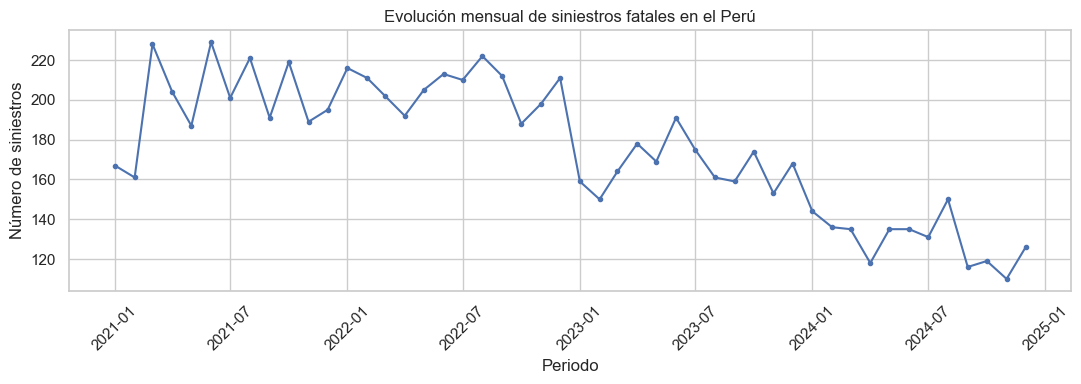

,Total de siniestros
periodo_fecha,
2021,2392
2022,2480
2023,2001
2024,1555


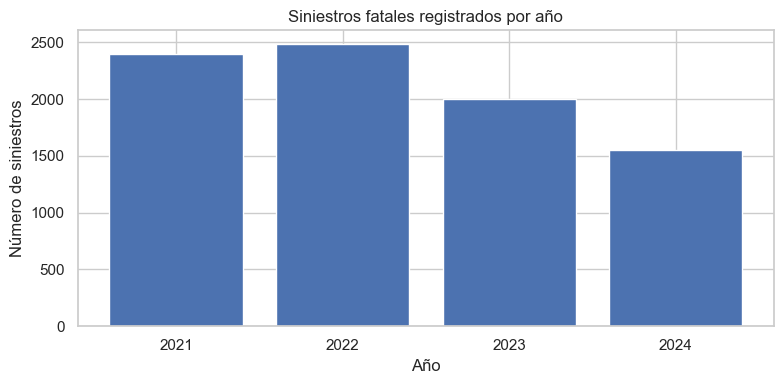

In [5]:
siniestros_mensuales = df.groupby("periodo_fecha")["siniestros"].sum().sort_index()

plt.figure(figsize=(11, 4))
plt.plot(siniestros_mensuales.index, siniestros_mensuales.values, marker="o", markersize=3)
plt.title("Evolución mensual de siniestros fatales en el Perú")
plt.xlabel("Periodo")
plt.ylabel("Número de siniestros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Totales anuales
siniestros_anuales = df.groupby(df["periodo_fecha"].dt.year)["siniestros"].sum()
display(siniestros_anuales.to_frame("Total de siniestros"))

plt.figure(figsize=(8, 4))
plt.bar(siniestros_anuales.index.astype(str), siniestros_anuales.values)
plt.title("Siniestros fatales registrados por año")
plt.xlabel("Año")
plt.ylabel("Número de siniestros")
plt.tight_layout()
plt.show()


**Interpretación:** Como los datos de 2024 aún son preliminares, la disminución observada podría deberse a que todavía faltan registros por completar.

## 6. Estacionalidad mensual
Se calcula el promedio de siniestros nacionales para cada mes del calendario.

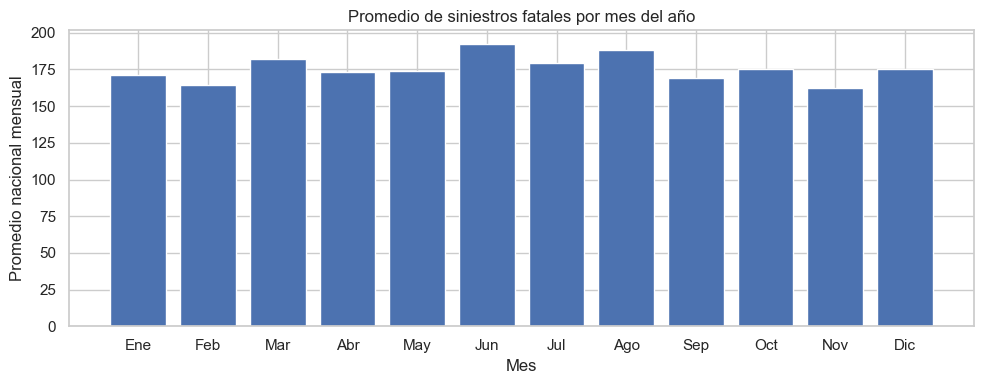

Mes de mayor promedio: Jun 192.0
Mes de menor promedio: Nov 162.5


In [6]:
promedio_mes = siniestros_mensuales.groupby(siniestros_mensuales.index.month).mean()
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

plt.figure(figsize=(10, 4))
plt.bar(meses, promedio_mes.reindex(range(1, 13)).values)
plt.title("Promedio de siniestros fatales por mes del año")
plt.xlabel("Mes")
plt.ylabel("Promedio nacional mensual")
plt.tight_layout()
plt.show()

print("Mes de mayor promedio:", meses[promedio_mes.idxmax()-1], round(promedio_mes.max(), 2))
print("Mes de menor promedio:", meses[promedio_mes.idxmin()-1], round(promedio_mes.min(), 2))

## 7. Comparación entre departamentos

,Total de siniestros
departamento,
LIMA,1785
LA LIBERTAD,829
PUNO,733
CUSCO,686
AREQUIPA,594
CAJAMARCA,483
PIURA,435
ICA,427
JUNIN,383


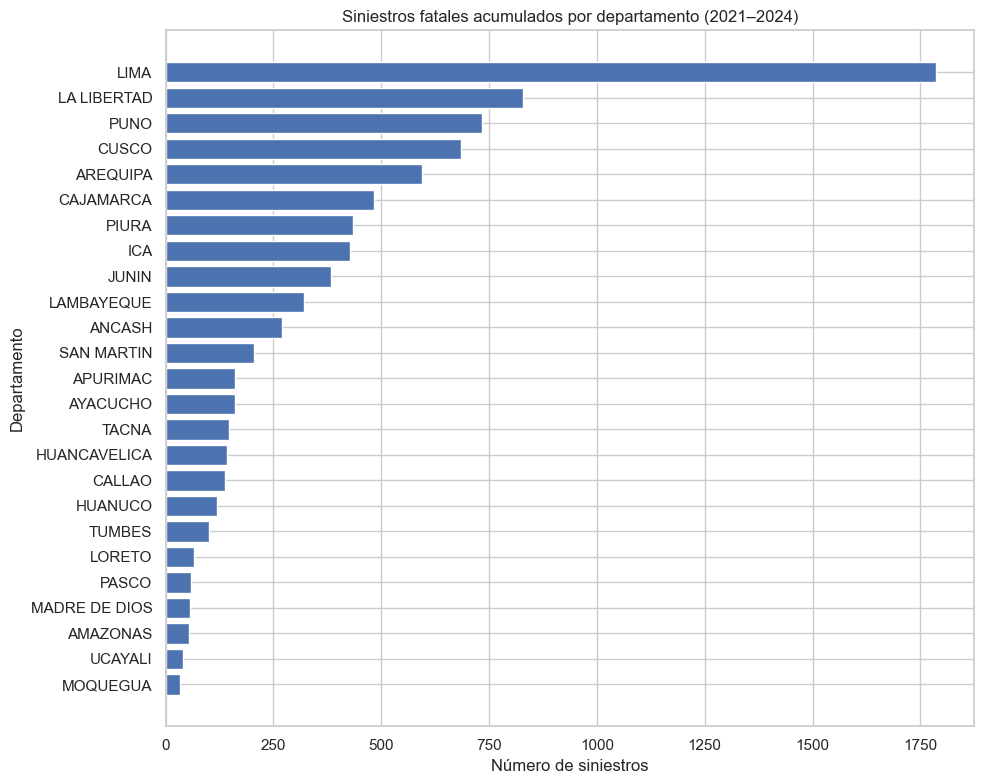

In [7]:
totales_depto = df.groupby("departamento")["siniestros"].sum().sort_values(ascending=False)

display(totales_depto.to_frame("Total de siniestros"))

plt.figure(figsize=(10, 8))
plt.barh(totales_depto.index[::-1], totales_depto.values[::-1])
plt.title("Siniestros fatales acumulados por departamento (2021–2024)")
plt.xlabel("Número de siniestros")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()


## 8. Distribución de la variable objetivo

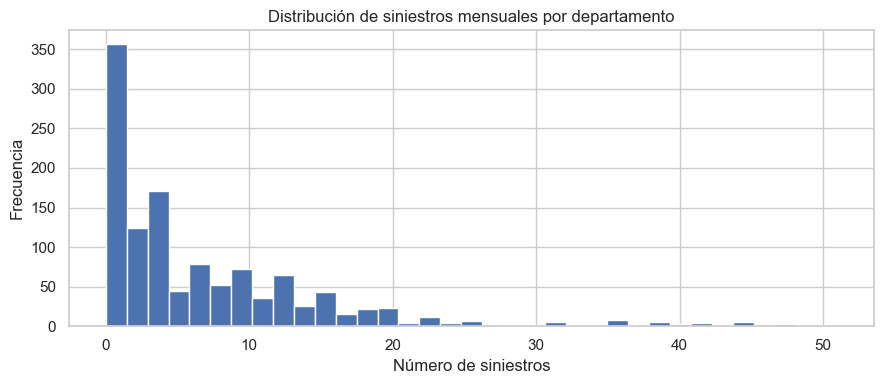

Observaciones con cero siniestros: 246
Porcentaje: 20.5 %


In [8]:
plt.figure(figsize=(9, 4))
plt.hist(df["siniestros"], bins=35)
plt.title("Distribución de siniestros mensuales por departamento")
plt.xlabel("Número de siniestros")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

print("Observaciones con cero siniestros:", (df["siniestros"] == 0).sum())
print("Porcentaje:", round((df["siniestros"] == 0).mean() * 100, 2), "%")


## 9. Valores atípicos mediante IQR
Los valores atípicos se identifican para describir la distribución, pero no se eliminan: pueden reflejar diferencias reales entre departamentos.

Q1: 1.0 | Q3: 11.0 | IQR: 10.0
Límites: -14.0 a 26.0
Observaciones atípicas: 45


,Cantidad
departamento,
LIMA,45


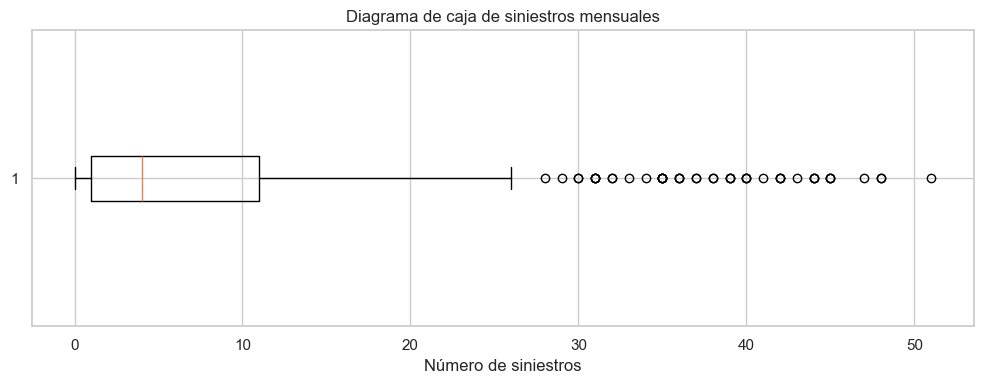

In [9]:
q1 = df["siniestros"].quantile(0.25)
q3 = df["siniestros"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = df[(df["siniestros"] < limite_inferior) | (df["siniestros"] > limite_superior)]
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Límites:", limite_inferior, "a", limite_superior)
print("Observaciones atípicas:", len(atipicos))
display(atipicos["departamento"].value_counts().to_frame("Cantidad"))

plt.figure(figsize=(10, 4))
plt.boxplot(df["siniestros"], vert=False)
plt.title("Diagrama de caja de siniestros mensuales")
plt.xlabel("Número de siniestros")
plt.tight_layout()
plt.show()


**Interpretación:** Se identificaron 45 valores atípicos, todos correspondientes a Lima, debido a que presenta una cantidad mensual de siniestros considerablemente mayor que los demás departamentos. Estos registros no se eliminarán, ya que no se ha identificado que sean errores y contienen información relevante para el análisis.

## 10. Correlación entre las variables del dataset de modelado
Se utiliza `dataset_modelo.csv` para analizar la relación entre los siniestros, los rezagos y el promedio móvil. Si algunas variables presentan correlaciones altas entre sí, podría existir multicolinealidad.

Dimensiones del dataset de modelado: (1125, 9)


,departamento,periodo,siniestros,lag_1,lag_2,lag_3,prom_movil_3,anio,mes
0,AMAZONAS,2021-04,1,2.0,2.0,4.0,2.666667,2021,4
1,AMAZONAS,2021-05,2,1.0,2.0,2.0,1.666667,2021,5
2,AMAZONAS,2021-06,0,2.0,1.0,2.0,1.666667,2021,6
3,AMAZONAS,2021-07,0,0.0,2.0,1.0,1.000000,2021,7
4,AMAZONAS,2021-08,2,0.0,0.0,2.0,0.666667,2021,8


,siniestros,lag_1,lag_2,lag_3,prom_movil_3,anio,mes
siniestros,1.000,0.893,0.882,0.881,0.921,-0.138,0.001
lag_1,0.893,1.000,0.890,0.880,0.960,-0.134,-0.012
lag_2,0.882,0.890,1.000,0.890,0.964,-0.123,-0.001
lag_3,0.881,0.880,0.890,1.000,0.960,-0.109,-0.006
prom_movil_3,0.921,0.960,0.964,0.960,1.000,-0.127,-0.006
anio,-0.138,-0.134,-0.123,-0.109,-0.127,1.000,-0.132
mes,0.001,-0.012,-0.001,-0.006,-0.006,-0.132,1.000


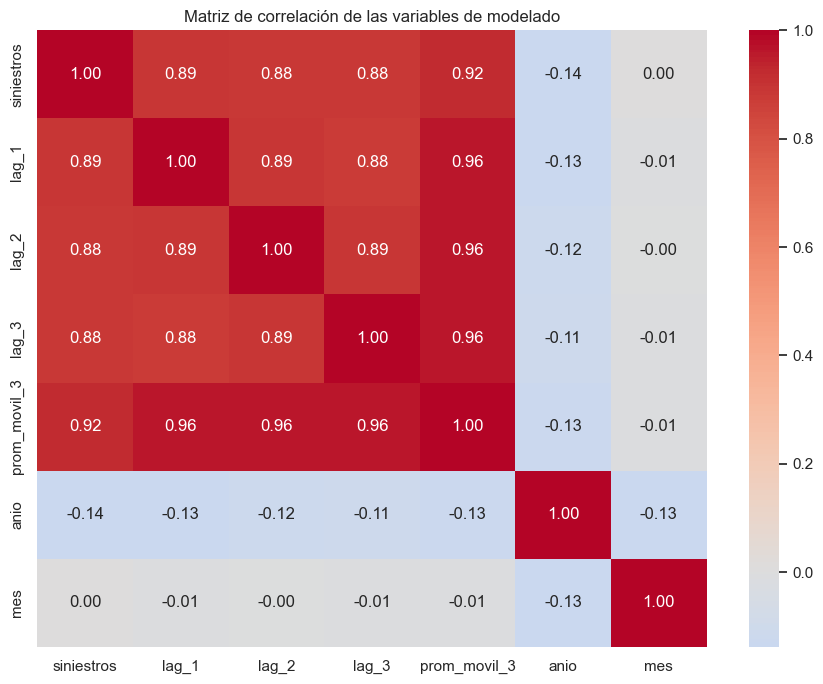

In [10]:
print("Dimensiones del dataset de modelado:", df_modelo.shape)
display(df_modelo.head())

variables = ["siniestros", "lag_1", "lag_2", "lag_3", "prom_movil_3", "anio", "mes"]
correlacion = df_modelo[variables].corr()
display(correlacion.round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación de las variables de modelado")
plt.tight_layout()
plt.show()


## 11. Conclusiones

1. **Distribución de siniestros:** De las 1200 observaciones, 246 (20,5 %) presentan cero siniestros registrados. Estos valores son válidos y se mantienen en el dataset.
2. **Diferencias entre departamentos:** Lima registra la mayor cantidad de siniestros (1785), seguida de La Libertad (829) y Puno (733). Estas diferencias muestran la importancia de considerar el departamento como variable predictora.
3. **Evolución temporal:** Los registros alcanzaron su mayor valor en 2022, con 2480 siniestros, y disminuyeron hasta 1555 en 2024. Sin embargo, los datos de este último año son preliminares, por lo que todavía no se puede asegurar que exista una reducción real de los siniestros.
4. **Valores atípicos y correlaciones:** Se identificaron 45 observaciones atípicas, todas correspondientes a Lima, que se conservaron al no existir evidencia de errores. Además, los rezagos y el promedio móvil presentan correlaciones de hasta 0,96, lo que indica una posible multicolinealidad que deberá considerarse al desarrollar los modelos.

_El EDA se realizó con los datasets preprocesados previamente. Los gráficos generados se guardan en la carpeta `results/plots/EDA` del proyecto._